## Importacion de bibliotecas

In [1]:
import yfinance as yf

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import mean_absolute_error, mean_squared_error
from IPython.display import display
from pathlib import Path
plt.style.use("seaborn-v0_8-whitegrid")
OUT=Path("resultados_IBM_WMT"); OUT.mkdir(exist_ok=True)
START="2021-10-22"; END="2026-10-23"
print("Bibliotecas listas")

Bibliotecas listas


##  Obtención y limpieza de precios históricos
Se utilizan precios ajustados por eventos corporativos mediante `auto_adjust=True`, que facilita la comparación temporal. El extremo final de Yahoo es exclusivo. La última fecha disponible puede ser anterior al día actual si aún no ha terminado la sesión.

In [3]:
raw=yf.download(["IBM","WMT"],start=START,end=END,auto_adjust=True,progress=False,threads=False)
if raw.empty: raise RuntimeError("Yahoo Finance no devolvió datos: comprueba Internet y vuelve a ejecutar.")
precios=raw["Close"].copy()
precios=precios[["IBM","WMT"]].dropna().sort_index()
if len(precios)<100: raise ValueError("Datos insuficientes para el análisis")
print("Rango efectivo:",precios.index.min().date(),"a",precios.index.max().date())
print("Observaciones:",len(precios))
display(precios.head(),precios.tail(),precios.describe().round(3))
precios.to_csv(OUT/"precios_ajustados.csv")

Rango efectivo: 2021-10-22 a 2026-10-22
Observaciones: 1255


Ticker,IBM,WMT
Date,,
2021-10-22,100.967659,46.448883
2021-10-25,100.778175,46.987461
2021-10-26,100.375496,46.577259
2021-10-27,98.827995,46.195244
2021-10-28,99.356972,46.483326


Ticker,IBM,WMT
Date,,
2026-10-16,232.139999,118.809998
2026-10-19,236.389999,118.699997
2026-10-20,241.919998,117.849998
2026-10-21,251.460007,117.800003
2026-10-22,252.110001,121.120003


Ticker,IBM,WMT
count,1255.000,1255.000
mean,180.254,72.753
std,63.719,28.659
min,96.920,37.468
25%,118.811,47.041
50%,169.412,59.052
75%,236.140,98.271
max,326.885,133.879


##  Evolución de los precios y rendimientos
El precio ajustado refleja la evolución de cada título. Los rendimientos porcentuales diarios permiten comparar variaciones relativas de empresas con diferentes niveles de precio.

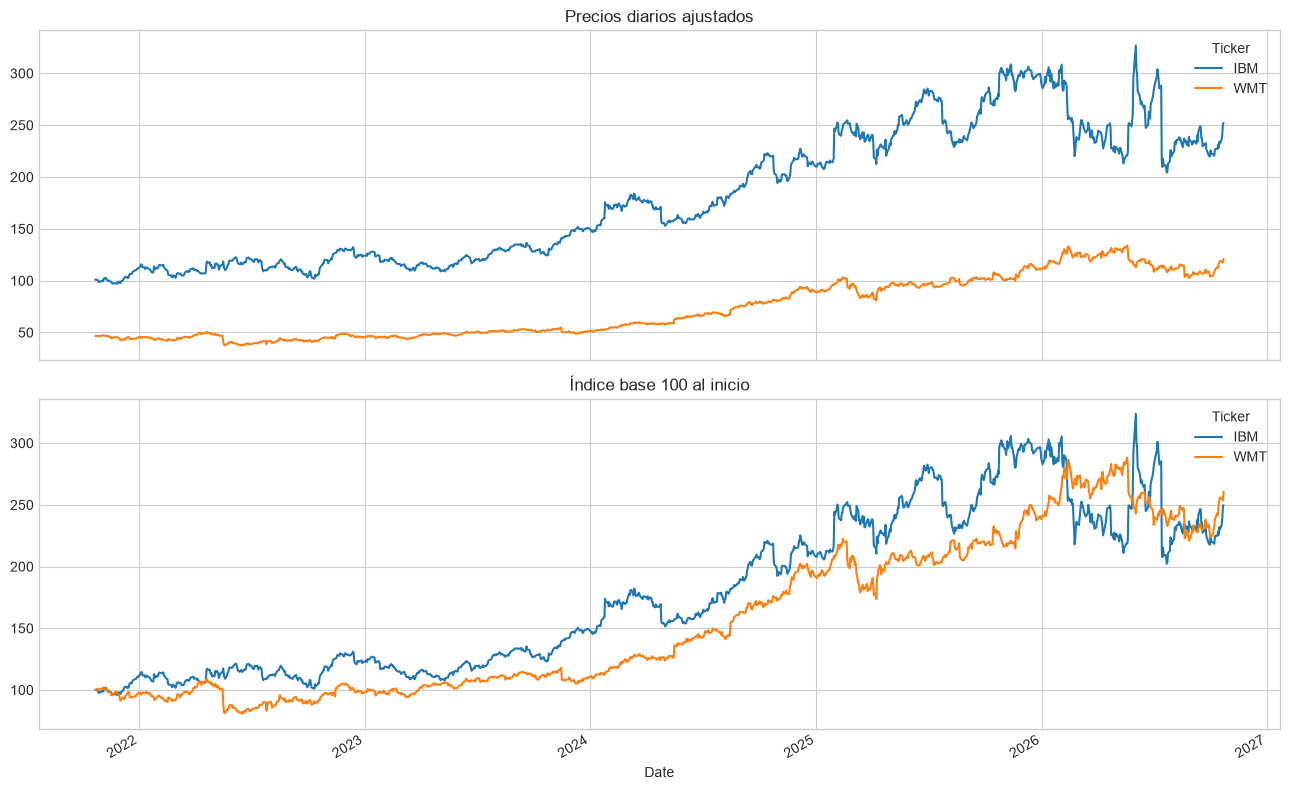

In [4]:
rend=precios.pct_change().dropna()
fig,axs=plt.subplots(2,1,figsize=(13,8),sharex=True)
precios.plot(ax=axs[0],title="Precios diarios ajustados")
(precios/precios.iloc[0]*100).plot(ax=axs[1],title="Índice base 100 al inicio")
plt.tight_layout();plt.savefig(OUT/"01_evolucion.png",dpi=160);plt.show()

## ¿Existe correlación entre IBM y Walmart?
Coeficiente de Pearson: $r=\frac{\mathrm{cov}(X,Y)}{\sigma_X\sigma_Y}$, entre −1 y 1. Correlación de precios no demuestra dependencia de rendimientos ni causalidad. El análisis considera ambos enfoques.

Pearson precios: 0.9261
Pearson rendimientos: 0.1101


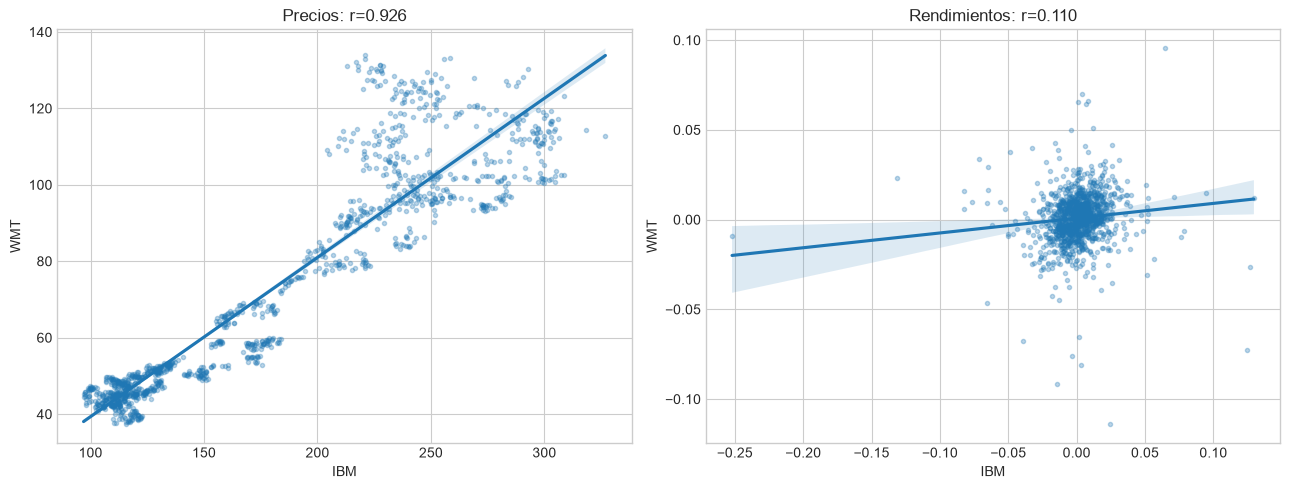

Interpretación: asociación positiva entre rendimientos; magnitud 0.11


In [5]:
r_p=precios["IBM"].corr(precios["WMT"]);r_r=rend["IBM"].corr(rend["WMT"])
print(f"Pearson precios: {r_p:.4f}")
print(f"Pearson rendimientos: {r_r:.4f}")
fig,axs=plt.subplots(1,2,figsize=(13,5))
sns.regplot(data=precios,x="IBM",y="WMT",ax=axs[0],scatter_kws={"alpha":.3,"s":9});axs[0].set_title(f"Precios: r={r_p:.3f}")
sns.regplot(data=rend,x="IBM",y="WMT",ax=axs[1],scatter_kws={"alpha":.3,"s":9});axs[1].set_title(f"Rendimientos: r={r_r:.3f}")
plt.tight_layout();plt.savefig(OUT/"02_correlacion.png",dpi=160);plt.show()
print("Interpretación:","asociación positiva" if r_r>0 else "asociación negativa" if r_r<0 else "ausencia de asociación lineal", "entre rendimientos; magnitud",abs(round(r_r,3)))

##  Descomposición temporal
Se emplea una descomposición aditiva con **periodo ilustrativo de 5 sesiones bursátiles**. Este parámetro representa una posible regularidad semanal, no prueba que exista estacionalidad. El modelo no debe interpretarse como evidencia causal.

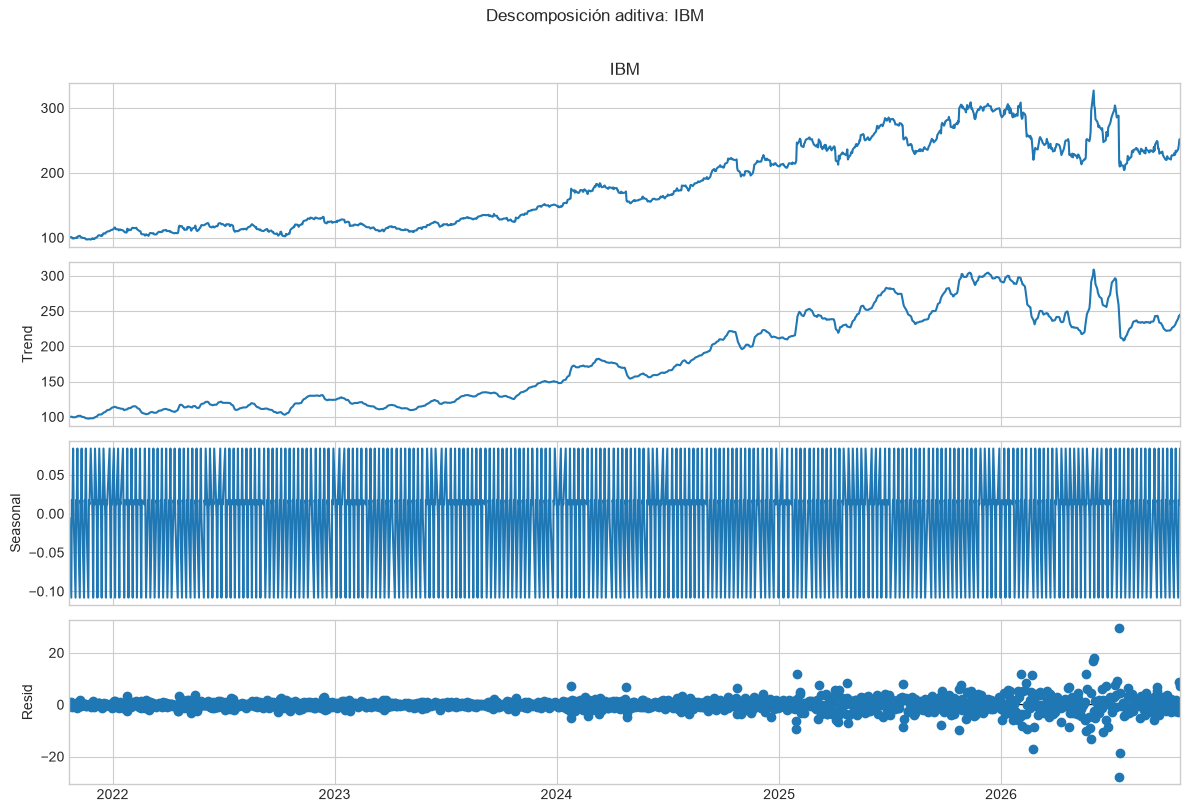

IBM amplitud estacional aproximada: 0.192


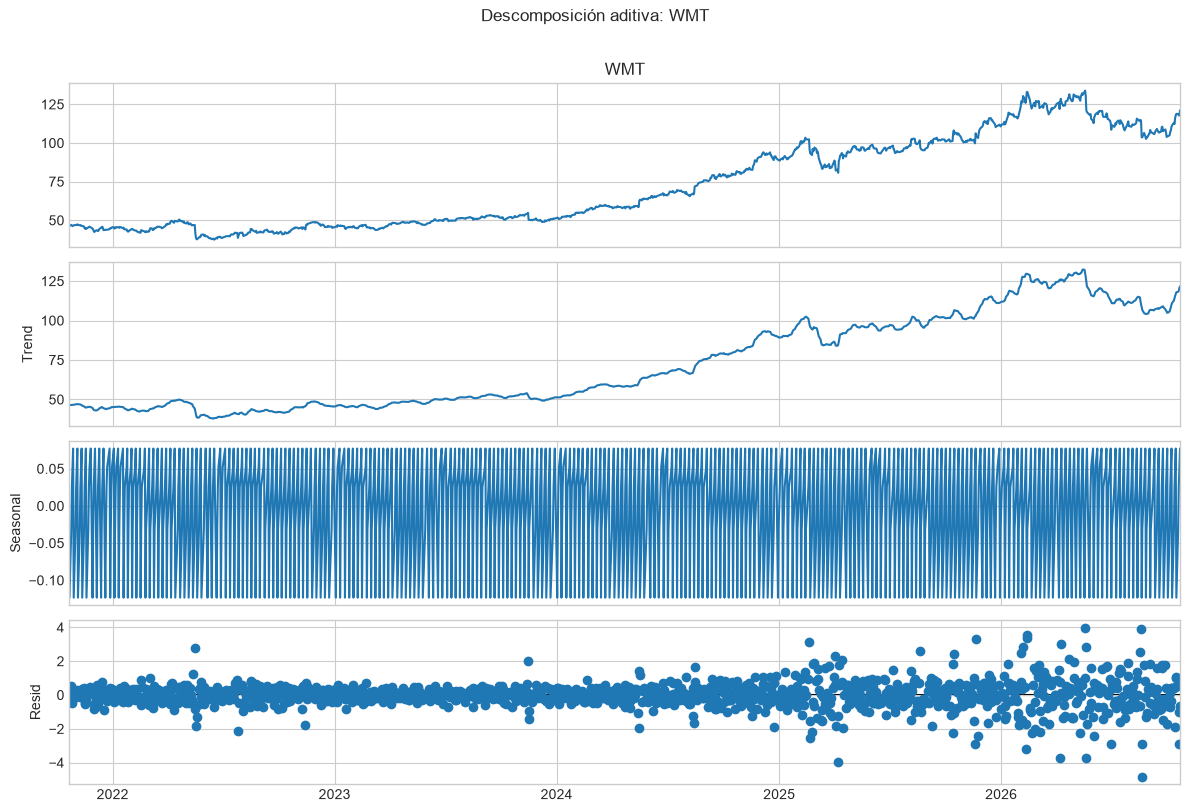

WMT amplitud estacional aproximada: 0.2


In [6]:
for ticker in precios.columns:
    d=seasonal_decompose(precios[ticker],model="additive",period=5,extrapolate_trend="freq")
    fig=d.plot();fig.set_size_inches(12,8);fig.suptitle(f"Descomposición aditiva: {ticker}",y=1.01)
    fig.tight_layout();fig.savefig(OUT/f"03_descomposicion_{ticker}.png",dpi=160);plt.show()
    print(ticker,"amplitud estacional aproximada:",round(d.seasonal.max()-d.seasonal.min(),3))

##  Correlogramas ACF y PACF
La ACF mide correlación con rezagos; la PACF estima asociación directa controlando rezagos intermedios. Una ACF de precios que decae lentamente suele ser compatible con persistencia/no estacionariedad; la ACF de diferencias o rendimientos es más útil para evaluar dependencia de corto plazo.

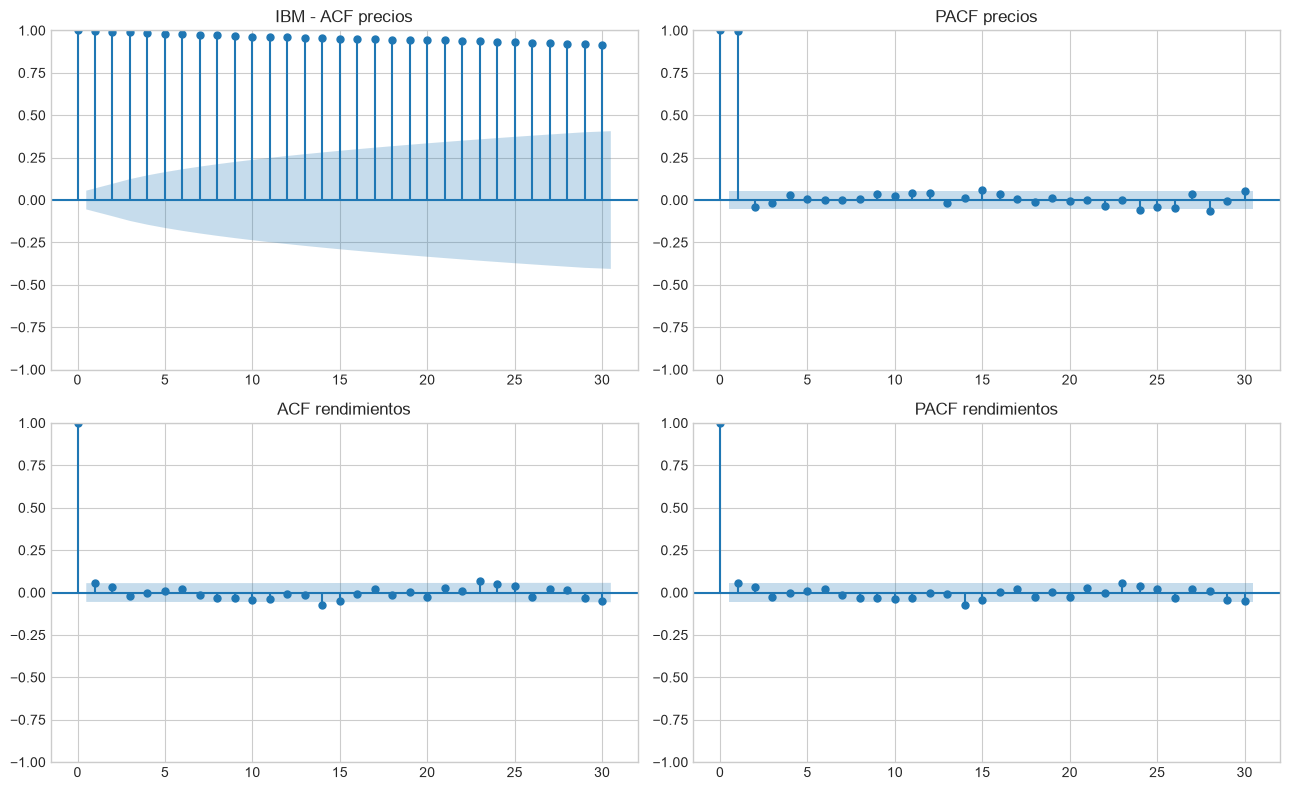

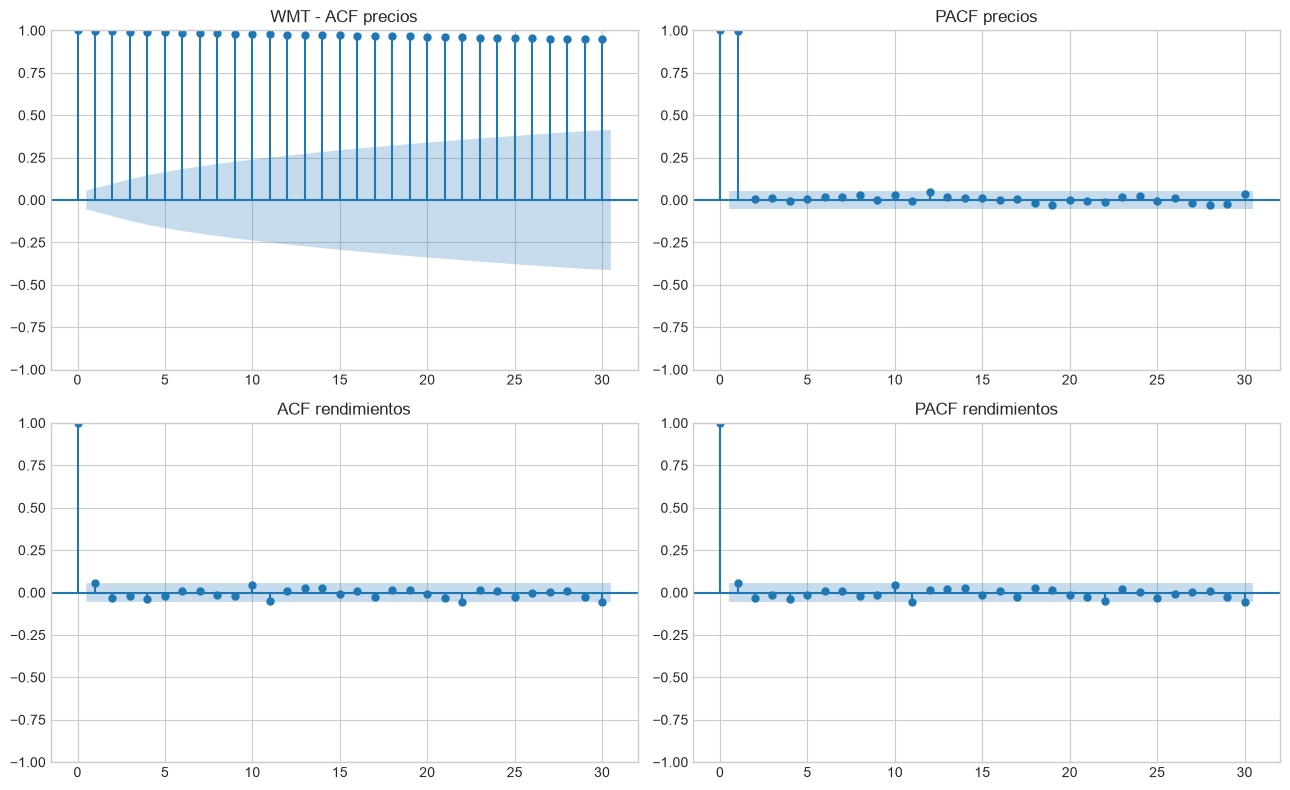

In [7]:
for ticker in precios.columns:
    fig,axs=plt.subplots(2,2,figsize=(13,8))
    plot_acf(precios[ticker],lags=30,ax=axs[0,0]);axs[0,0].set_title(f"{ticker} - ACF precios")
    plot_pacf(precios[ticker],lags=30,ax=axs[0,1],method="ywm");axs[0,1].set_title("PACF precios")
    plot_acf(rend[ticker],lags=30,ax=axs[1,0]);axs[1,0].set_title("ACF rendimientos")
    plot_pacf(rend[ticker],lags=30,ax=axs[1,1],method="ywm");axs[1,1].set_title("PACF rendimientos")
    plt.tight_layout();plt.savefig(OUT/f"04_correlogramas_{ticker}.png",dpi=160);plt.show()

##  Prueba Dickey-Fuller aumentada (ADF)
**H₀:** la serie presenta raíz unitaria (no estacionaria). **H₁:** no presenta raíz unitaria, bajo la especificación de la prueba. Se utiliza $\alpha=0.05$. Si $p<0.05$, se rechaza H₀; si no, no se rechaza. La prueba no demuestra por sí sola estacionariedad completa.

In [8]:
def tabla_adf(serie,empresa,tipo):
    stat,pv,lag,nobs,crit,ic=adfuller(serie.dropna(),autolag="AIC")
    return {"Empresa":empresa,"Serie":tipo,"ADF":stat,"p-valor":pv,"Rezagos":lag,"N":nobs,"Crítico 5%":crit["5%"],"Decisión":("Rechazar H0" if pv<.05 else "No rechazar H0")}
resultados_adf=pd.DataFrame([tabla_adf(s,t,tipo) for tipo,datos in [("Precio",precios),("Rendimiento",rend)] for t,s in datos.items()])
display(resultados_adf.round(5));resultados_adf.to_csv(OUT/"adf.csv",index=False)
for _,r in resultados_adf.iterrows(): print(f"{r.Empresa} ({r.Serie}): p={r[chr(112)+chr(45)+chr(118)+chr(97)+chr(108)+chr(111)+chr(114)]:.5g}; {r[chr(68)+chr(101)+chr(99)+chr(105)+chr(115)+chr(105)+chr(243)+chr(110)]} al 5%")

,Empresa,Serie,ADF,p-valor,Rezagos,N,Crítico 5%,Decisión
0,IBM,Precio,-1.09822,0.71578,15,1239,-2.86388,No rechazar H0
1,WMT,Precio,-0.06314,0.95299,2,1252,-2.86385,No rechazar H0
2,IBM,Rendimiento,-33.49730,0.00000,0,1253,-2.86385,Rechazar H0
3,WMT,Rendimiento,-33.33680,0.00000,0,1253,-2.86385,Rechazar H0


IBM (Precio): p=0.71578; No rechazar H0 al 5%
WMT (Precio): p=0.95299; No rechazar H0 al 5%
IBM (Rendimiento): p=0; Rechazar H0 al 5%
WMT (Rendimiento): p=0; Rechazar H0 al 5%


##  Promedios móviles simples
El promedio móvil simple de ventana $k$ es $SMA_k(t)=\frac{1}{k}\sum_{i=0}^{k-1}P_{t-i}$. Se comparan ventanas de 5, 10, 20 y 50 sesiones. Son estimadores rezagados, sensibles a cambios bruscos de tendencia.

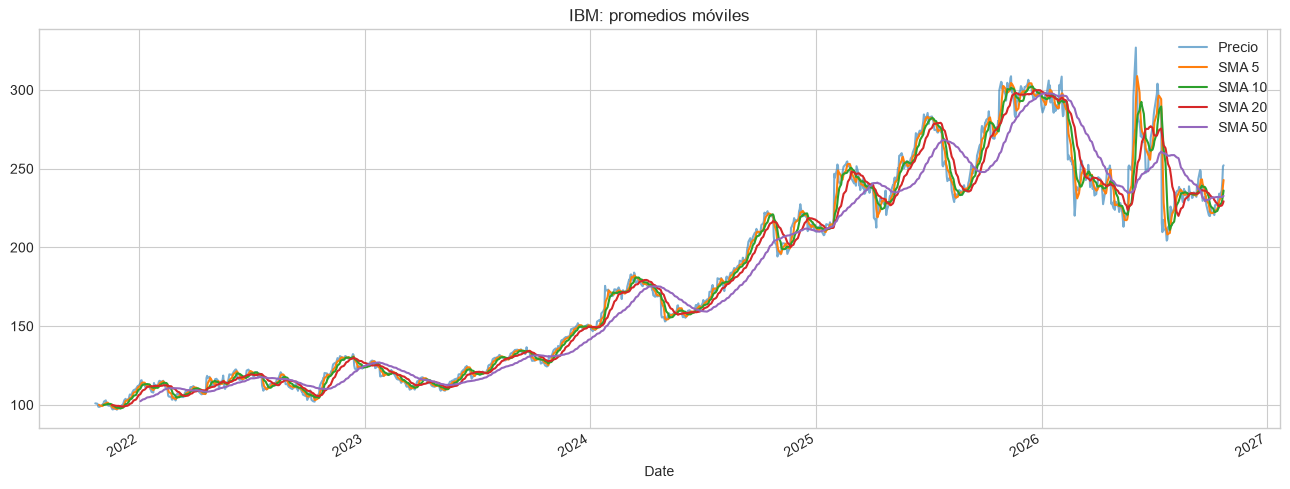

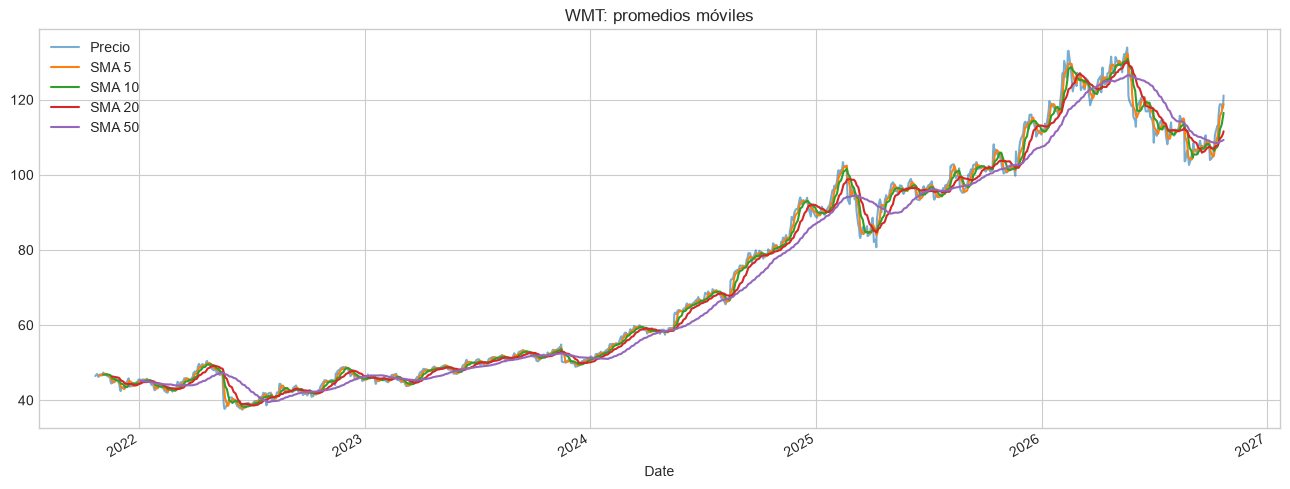

In [9]:
ventanas=[5,10,20,50]
for ticker in precios.columns:
    fig,ax=plt.subplots(figsize=(13,5));precios[ticker].plot(ax=ax,label="Precio",alpha=.6)
    for k in ventanas:precios[ticker].rolling(k).mean().plot(ax=ax,label=f"SMA {k}")
    ax.set_title(f"{ticker}: promedios móviles");ax.legend();plt.tight_layout();plt.savefig(OUT/f"05_medias_{ticker}.png",dpi=160);plt.show()

##  Evaluación retrospectiva sin fuga de información
Se evalúan los pronósticos de un paso adelante usando exclusivamente los $k$ precios previos. Se reserva el último 20% cronológico para prueba; MAE y RMSE se comparan con el modelo ingenuo $\hat P_{t+1}=P_t$. Seleccionar la ventana usando este mismo conjunto de prueba sería optimista: aquí se muestran todas las ventanas y se declara la comparación exploratoria.

In [10]:
filas=[]
for ticker in precios.columns:
    s=precios[ticker];cut=int(len(s)*.8)
    for k in ventanas:
        pred=s.shift(1).rolling(k).mean();valid=pred.iloc[cut:].dropna();real=s.loc[valid.index]
        filas.append({"Empresa":ticker,"Método":f"SMA{k}","MAE":mean_absolute_error(real,valid),"RMSE":np.sqrt(mean_squared_error(real,valid))})
    pred=s.shift(1).iloc[cut:].dropna();real=s.loc[pred.index]
    filas.append({"Empresa":ticker,"Método":"Ingenuo","MAE":mean_absolute_error(real,pred),"RMSE":np.sqrt(mean_squared_error(real,pred))})
metricas=pd.DataFrame(filas);display(metricas.round(4));metricas.to_csv(OUT/"metricas.csv",index=False)

,Empresa,Método,MAE,RMSE
0,IBM,SMA5,8.3921,13.1238
1,IBM,SMA10,11.2127,17.2878
2,IBM,SMA20,13.4803,20.1882
3,IBM,SMA50,19.9021,25.4695
4,IBM,Ingenuo,5.0380,8.2757
5,WMT,SMA5,2.2060,2.9197
6,WMT,SMA10,2.8398,3.7912
7,WMT,SMA20,3.5515,4.6414
8,WMT,SMA50,5.3946,6.4739
9,WMT,Ingenuo,1.3925,1.9414


##  Pronóstico del siguiente día bursátil
Se presentan los pronósticos SMA5, SMA10, SMA20 y SMA50 con los últimos datos efectivamente disponibles. La fecha exacta de la siguiente sesión depende del calendario bursátil estadounidense; por eso se indica «siguiente sesión» sin asumir que será el día natural siguiente.

In [11]:
pronosticos=pd.DataFrame([{"Empresa":ticker,"Última fecha":str(precios.index[-1].date()),"Último precio":precios[ticker].iloc[-1],**{f"SMA{k}":precios[ticker].tail(k).mean() for k in ventanas}} for ticker in precios.columns])
display(pronosticos.round(4));pronosticos.to_csv(OUT/"pronosticos_siguiente_sesion.csv",index=False)
for _,r in pronosticos.iterrows():print(f"{r.Empresa}: próxima sesión SMA5={r.SMA5:.2f}, SMA10={r.SMA10:.2f}, SMA20={r.SMA20:.2f}, SMA50={r.SMA50:.2f} USD")

,Empresa,Última fecha,Último precio,SMA5,SMA10,SMA20,SMA50
0,IBM,2026-10-22,252.11,242.804,236.095,229.265,232.7116
1,WMT,2026-10-22,121.12,118.856,116.502,111.598,109.3140


IBM: próxima sesión SMA5=242.80, SMA10=236.10, SMA20=229.26, SMA50=232.71 USD
WMT: próxima sesión SMA5=118.86, SMA10=116.50, SMA20=111.60, SMA50=109.31 USD


##  ¿Serían buenos estos pronósticos?
**No se debe asumir que serán buenos.** El promedio móvil suaviza ruido pero retrasa los cambios de tendencia y no incorpora noticias, anuncios financieros, eventos macroeconómicos o volatilidad futura. Una ADF que no rechaza raíz unitaria en precios y una ACF persistente aconsejan cautela. La conclusión empírica depende de MAE/RMSE de prueba frente al pronóstico ingenuo; si SMA no mejora al ingenuo, no existe evidencia de utilidad predictiva superior. Para seleccionar ventanas formalmente conviene validación temporal anidada o ventana expansiva.

##  Conclusiones
Al ejecutar el cuaderno, reportar: (1) los dos coeficientes de Pearson; (2) tendencia, estacionalidad y residuos; (3) ACF/PACF en precios y rendimientos; (4) ADF y decisión al 5%; (5) pronósticos SMA y errores retrospectivos. La correlación no implica causalidad ni garantiza predictibilidad.